# Ponderaciones intermedias y submuestreo

## 1. Entorno y configuración del experimento

In [1]:
from pathlib import Path
from textwrap import fill
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "cfpb_complaints_2023-06-01_2024-05-31").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encuentra el corte CFPB en su carpeta original.")
for folder in [ROOT / "Baseline", ROOT / "Modelado"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from baseline import cargar_datos, crear_particiones, auditar_particiones
from ponderacion import comparar_ponderacion, BASE, WEIGHTED, UNDERSAMPLED
plt.rcParams.update({"figure.dpi":110, "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})
display(pd.Series({
    "Comparación": "Sin pesos; balanced; exponentes 0,25 y 0,5; submuestreo Credit reporting",
    "Pesos intermedios": "balanced ** α, normalizados a peso medio 1 en entrenamiento",
    "Submuestreo": "Solo Credit reporting, hasta el tamaño de la segunda clase; aleatorio, semilla 42",
    "Vectorización": "Común en ponderaciones; TF-IDF propio ajustado en la muestra reducida para submuestreo",
    "Evaluación": "Misma validación con distribución original; prueba reservada",
    "Comparabilidad": "Mismos parámetros de regresión y particiones; sin combinar pesos y submuestreo",
    "Resultados": "En este notebook; sin exportar datos ni modelos",
}, name="Protocolo").to_frame())


,Protocolo
Comparación,"Sin pesos; balanced; exponentes 0,25 y 0,5; su..."
Pesos intermedios,"balanced ** α, normalizados a peso medio 1 en ..."
Submuestreo,"Solo Credit reporting, hasta el tamaño de la s..."
Vectorización,Común en ponderaciones; TF-IDF propio ajustado...
Evaluación,Misma validación con distribución original; pr...
Comparabilidad,Mismos parámetros de regresión y particiones; ...
Resultados,En este notebook; sin exportar datos ni modelos


## 2. Datos y particiones compartidas con el baseline

In [2]:
datos = cargar_datos(ROOT)
particiones = crear_particiones(datos)
auditoria = auditar_particiones(datos, particiones)
display(auditoria["resumen"].round(2))
display(auditoria["soporte"])

,Filas,% del corte,Clases,Textos distintos,Fecha mínima,Fecha máxima
Partición,,,,,,
Entrenamiento,407741,70.0,11,266428,2023-06-01,2024-05-31
Validación,87374,15.0,11,64464,2023-06-01,2024-05-31
Prueba,87374,15.0,11,64387,2023-06-01,2024-05-31


,Entrenamiento,Validación,Prueba
Product,,,
Credit reporting or other personal consumer reports,294854,63184,63184
Debt collection,34807,7459,7459
Credit card,26609,5702,5702
Checking or savings account,19070,4087,4086
Mortgage,8444,1810,1810
"Money transfer, virtual currency, or money service",6324,1355,1355
Student loan,5925,1269,1270
Vehicle loan or lease,5053,1083,1083
"Payday loan, title loan, personal loan, or advance loan",3279,702,702


## 3. Entrenamiento, pesos y tamaño de las muestras

In [3]:
experimento = comparar_ponderacion(datos, particiones, ampliado=True)
display(experimento["pesos"].round(4))
display(experimento["muestra"])
display(experimento["ajustes"].round(2))
assert experimento["prueba_evaluada"] is False


Ajustando Sin ponderación: 407,741 filas


Sin ponderación: 109.1 s; macro-F1=0.6691


Ajustando Ponderación por clase: 407,741 filas


Ponderación por clase: 123.2 s; macro-F1=0.6619


Ajustando Ponderación α=0.25: 407,741 filas


...

Ajustando Submuestreo Credit reporting: 147,694 filas


Submuestreo Credit reporting: 50.1 s; macro-F1=0.6726


,Filas en entrenamiento,Peso,Peso total de la clase,Ponderación α=0.25,Ponderación α=0.5
Product,,,,,
Checking or savings account,19070,1.9438,37067.3636,1.5273,1.9862
Credit card,26609,1.3930,37067.3636,1.4053,1.6814
Credit reporting or other personal consumer reports,294854,0.1257,37067.3636,0.7702,0.5051
Debt collection,34807,1.0649,37067.3636,1.3140,1.4701
Debt or credit management,805,46.0464,37067.3636,3.3695,9.6670
"Money transfer, virtual currency, or money service",6324,5.8614,37067.3636,2.0126,3.4490
Mortgage,8444,4.3898,37067.3636,1.8723,2.9848
"Payday loan, title loan, personal loan, or advance loan",3279,11.3045,37067.3636,2.3718,4.7898
Prepaid card,2571,14.4175,37067.3636,2.5205,5.4093


,Original,Submuestreo
Product,,
Checking or savings account,19070,19070
Credit card,26609,26609
Credit reporting or other personal consumer reports,294854,34807
Debt collection,34807,34807
Debt or credit management,805,805
"Money transfer, virtual currency, or money service",6324,6324
Mortgage,8444,8444
"Payday loan, title loan, personal loan, or advance loan",3279,3279
Prepaid card,2571,2571


,Modelo,Filas entrenamiento,Vectorización (s),Vocabulario,Ajuste clasificador (s),Iteraciones,Avisos
0,Sin ponderación,407741,135.24,80000,109.10,55,Sin avisos
1,Ponderación por clase,407741,135.24,80000,123.20,72,Sin avisos
2,Ponderación α=0.25,407741,135.24,80000,177.90,74,Sin avisos
3,Ponderación α=0.5,407741,135.24,80000,172.53,72,Sin avisos
4,Submuestreo Credit reporting,147694,77.18,80000,50.06,65,Sin avisos


## 4. Comparación global en validación

,Accuracy,Macro-F1,F1 ponderada
Modelo,,,
Sin ponderación,0.9012,0.6691,0.8966
Ponderación por clase,0.8488,0.6619,0.8621
Ponderación α=0.25,0.9082,0.7223,0.9076
Ponderación α=0.5,0.8952,0.7239,0.8984
Submuestreo Credit reporting,0.8665,0.6726,0.8735


,Accuracy,Macro-F1,F1 ponderada
Modelo,,,
Sin ponderación,0.0000,0.0000,0.0000
Ponderación por clase,-0.0524,-0.0072,-0.0345
Ponderación α=0.25,0.0069,0.0532,0.0109
Ponderación α=0.5,-0.0060,0.0547,0.0018
Submuestreo Credit reporting,-0.0347,0.0034,-0.0232


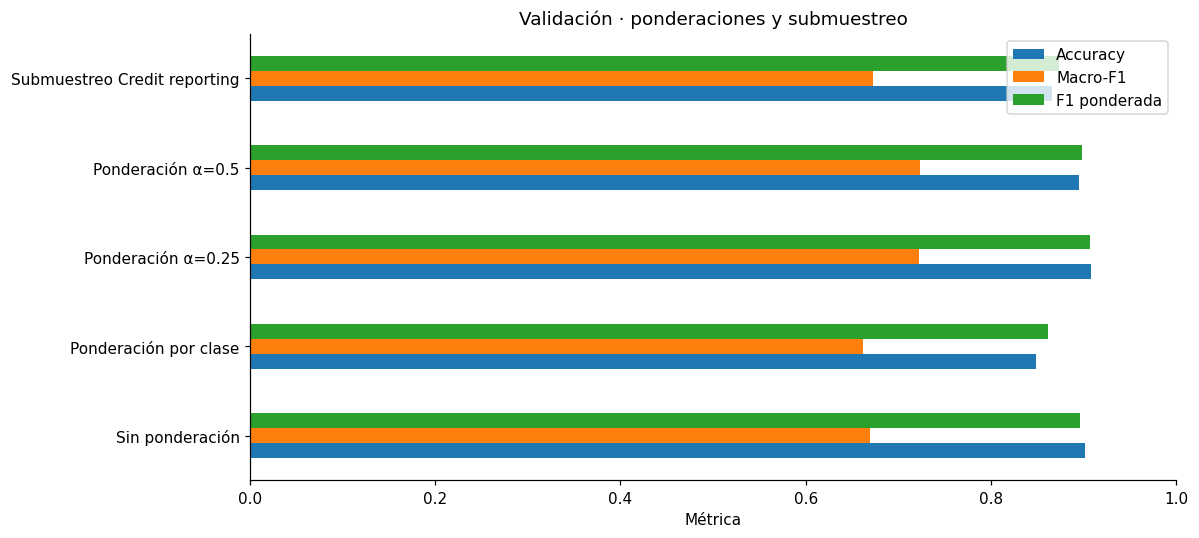

In [4]:
display(experimento["metricas"].round(4))
display(experimento["cambios"].round(4))
fig, ax = plt.subplots(figsize=(11,5))
experimento["metricas"].plot.barh(ax=ax)
ax.set(title="Validación · ponderaciones y submuestreo", xlabel="Métrica", ylabel="", xlim=(0,1))
plt.tight_layout(); plt.show()


## 5. Efecto en cada categoría

,Sin ponderación,Ponderación por clase,Ponderación α=0.25,Ponderación α=0.5,Submuestreo Credit reporting
Checking or savings account,0.7970,0.7932,0.8144,0.8150,0.8035
Credit card,0.7802,0.7434,0.7939,0.7813,0.7546
Credit reporting or other personal consumer reports,0.9548,0.9180,0.9585,0.9497,0.9293
Debt collection,0.7264,0.6805,0.7608,0.7436,0.6750
Debt or credit management,0.0000,0.1258,0.2111,0.3072,0.0000
"Money transfer, virtual currency, or money service",0.6612,0.6856,0.6957,0.7043,0.6978
Mortgage,0.8601,0.8384,0.8837,0.8686,0.8583
"Payday loan, title loan, personal loan, or advance loan",0.4086,0.4609,0.5529,0.5489,0.5089
Prepaid card,0.6782,0.7090,0.7274,0.7449,0.7132
Student loan,0.8632,0.8005,0.8834,0.8670,0.8327


precision  \
Modelo                       Product                                                         
Sin ponderación              Checking or savings account                            0.7594   
                             Credit card                                            0.7807   
                             Credit reporting or other personal consumer rep...     0.9394   
                             Debt collection                                        0.7917   
                             Debt or credit management                              0.0000   
                             Money transfer, virtual currency, or money service     0.7488   
                             Mortgage                                               0.8610   
                             Payday loan, title loan, personal loan, or adva...     0.6582   
                             Prepaid card                                           0.9361   
                             Student loan                                           0.8876   
                             Vehicle loan or lease                                  0.7182   
Ponderación por clase        Checking or savings account                            0.7812   
                             Credit card                                            0.6795   
                             Credit reporting or other personal consumer rep...     0.9844   
                             Debt collection                                        0.5808   
                             Debt or credit management                              0.0780   
                             Money transfer, virtual currency, or money service     0.6194   
                             Mortgage                                               0.7679   
                             Payday loan, title loan, personal loan, or adva...     0.3433   
                             Prepaid card                                           0.6435   
                             Student loan                                           0.7028   
                             Vehicle loan or lease                                  0.3946   
Ponderación α=0.25           Checking or savings account                            0.7783   
                             Credit card                                            0.7834   
                             Credit reporting or other personal consumer rep...     0.9598   
                             Debt collection                                        0.7616   
                             Debt or credit management                              0.7778   
                             Money transfer, virtual currency, or money service     0.7276   
                             Mortgage                                               0.8675   
                             Payday loan, title loan, personal loan, or adva...     0.5941   
                             Prepaid card                                           0.7812   
                             Student loan                                           0.8923   
                             Vehicle loan or lease                                  0.6609   
Ponderación α=0.5            Checking or savings account                            0.7867   
                             Credit card                                            0.7420   
                             Credit reporting or other personal consumer rep...     0.9712   
                             Debt collection                                        0.7000   
                             Debt or credit management                              0.3064   
                             Money transfer, virtual currency, or money service     0.6918   
                             Mortgage                                               0.8282   
                             Payday loan, title loan, personal loan, or adva...     0.4983   
                             Prepaid ca

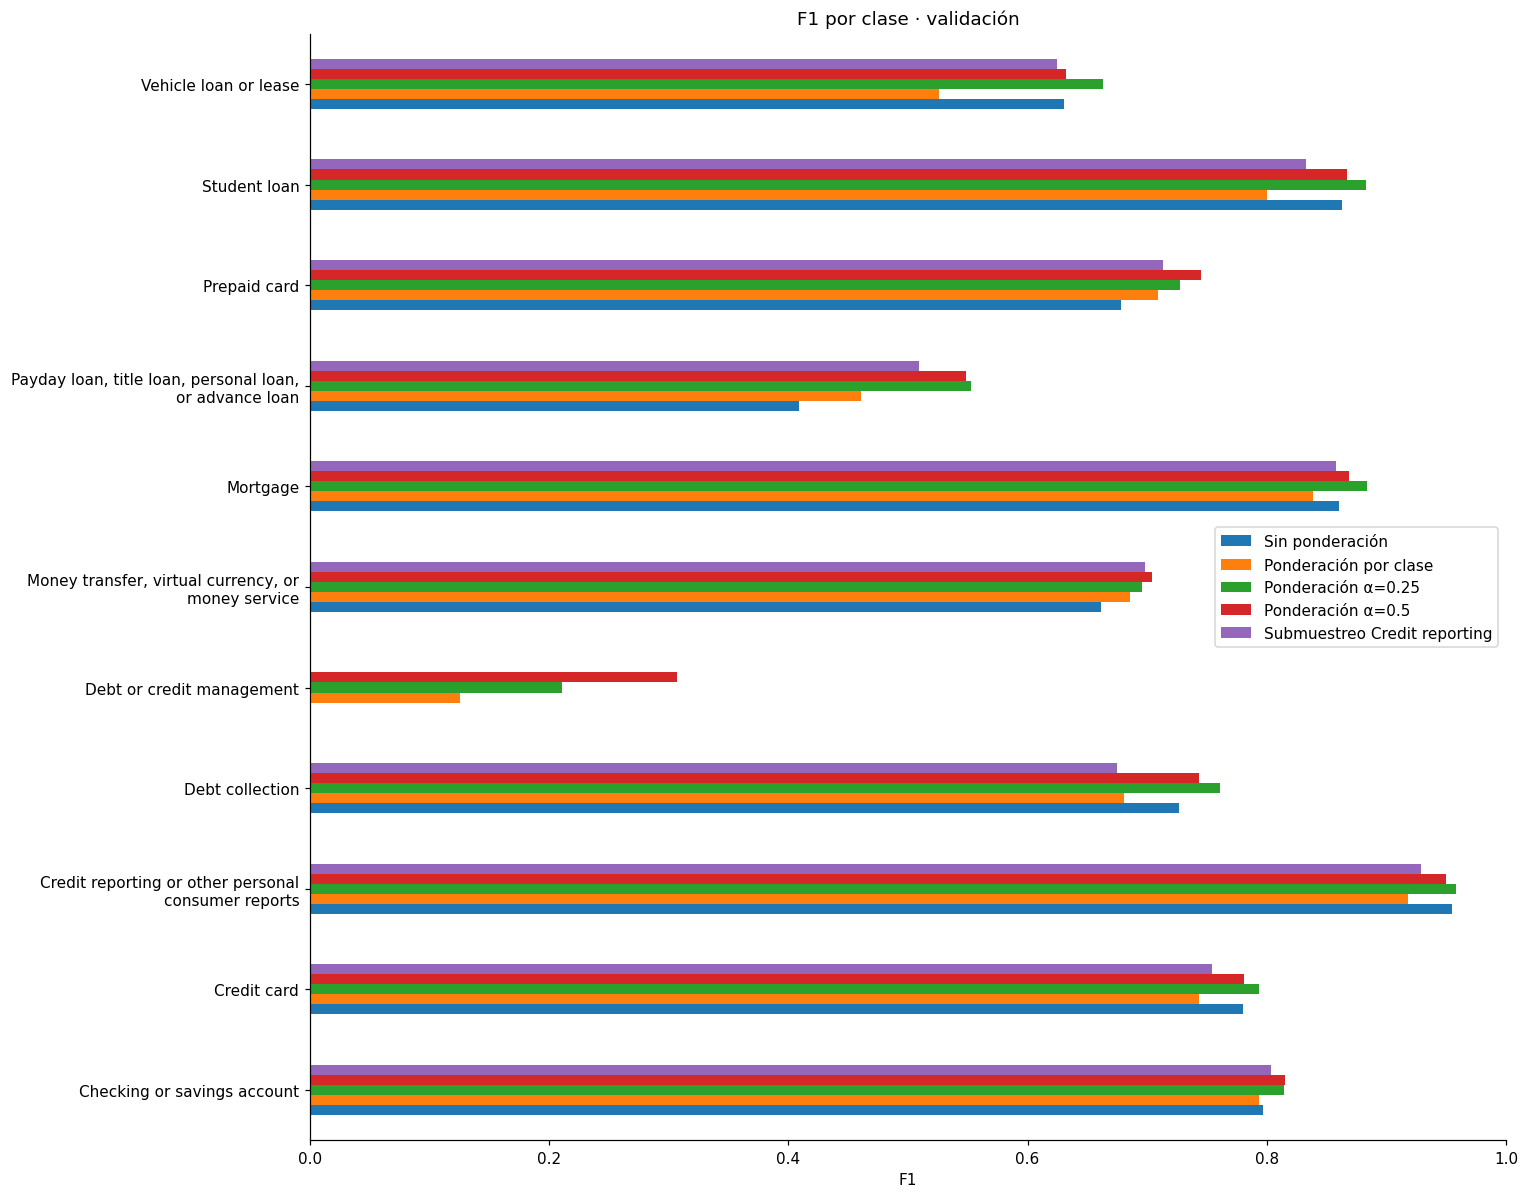

In [5]:
f1_comparison = pd.DataFrame({name: report["f1-score"] for name, report in experimento["reportes"].items()})
display(f1_comparison.round(4))
per_class = pd.concat(experimento["reportes"], names=["Modelo", "Product"])
with pd.option_context('display.max_rows', 100):
    display(per_class.round(4))
f1_plot = f1_comparison.copy()
f1_plot.index = [fill(label,40) for label in f1_plot.index]
fig, ax = plt.subplots(figsize=(14,11))
f1_plot.plot.barh(ax=ax)
ax.set(title="F1 por clase · validación", xlabel="F1", ylabel="", xlim=(0,1))
plt.tight_layout(); plt.show()


## 6. Resultados por empresa y exposición previa del texto

In [6]:
# Macro-F1 usa las mismas 11 etiquetas en todos los subgrupos; se muestra su soporte.
display(experimento["empresas"].round(4))

,Empresa / grupo,Modelo,Filas,Clases presentes,Accuracy,Macro-F1,F1 ponderada
0,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Sin ponderación,20842,8,0.9658,0.2519,0.9657
1,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Ponderación por clase,20842,8,0.8981,0.2149,0.9207
2,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Ponderación α=0.25,20842,8,0.9633,0.2526,0.9649
3,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Ponderación α=0.5,20842,8,0.9488,0.2416,0.9548
4,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Submuestreo Credit reporting,20842,8,0.9119,0.2144,0.9278
5,"EQUIFAX, INC.",Sin ponderación,20305,8,0.9701,0.2884,0.9704
6,"EQUIFAX, INC.",Ponderación por clase,20305,8,0.9088,0.2312,0.9301
7,"EQUIFAX, INC.",Ponderación α=0.25,20305,8,0.9676,0.2963,0.9694
8,"EQUIFAX, INC.",Ponderación α=0.5,20305,8,0.9532,0.2712,0.9595
9,"EQUIFAX, INC.",Submuestreo Credit reporting,20305,8,0.9234,0.2704,0.9378


## 7. Matriz de confusión del submuestreo

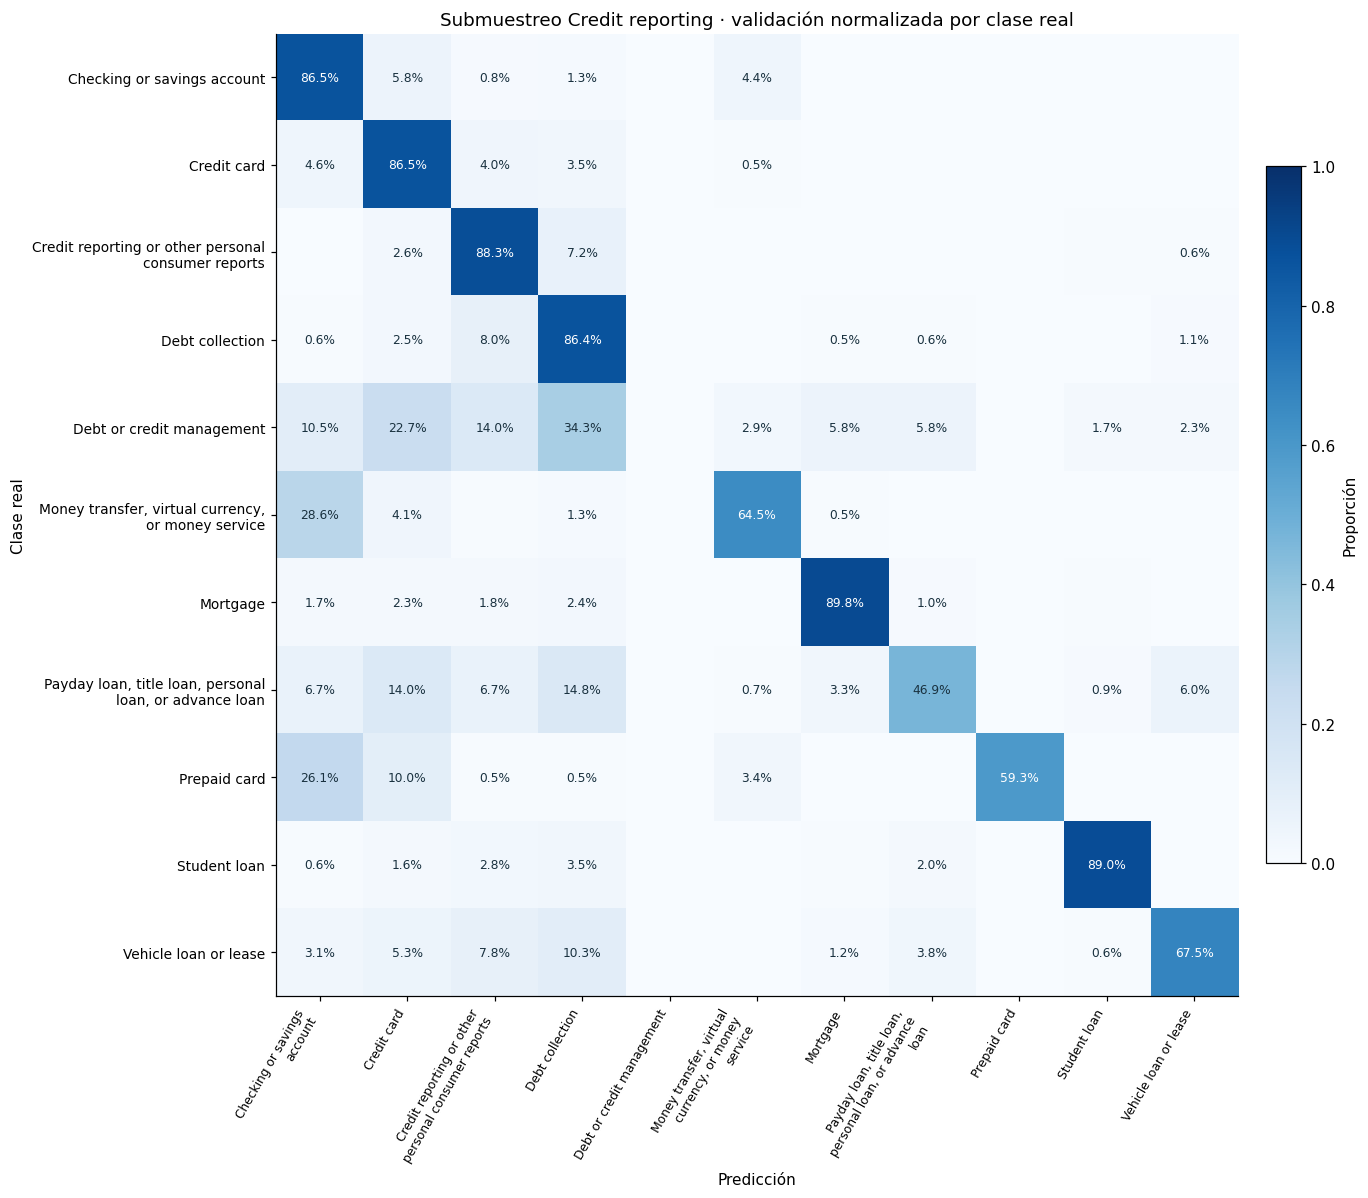

In [7]:
labels = experimento["labels"]
matrix = experimento["matrices"][UNDERSAMPLED]
fig, ax = plt.subplots(figsize=(14,11))
image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(labels)), [fill(p,25) for p in labels], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), [fill(p,35) for p in labels], fontsize=9)
for row in range(len(labels)):
    for col in range(len(labels)):
        if matrix[row,col]>=.005:
            ax.text(col,row,f"{matrix[row,col]:.1%}",ha="center",va="center",fontsize=8,
                    color="white" if matrix[row,col]>.5 else "#19313f")
ax.set(title="Submuestreo Credit reporting · validación normalizada por clase real", xlabel="Predicción", ylabel="Clase real")
fig.colorbar(image, ax=ax, fraction=.025, pad=.02, label="Proporción")
plt.tight_layout(); plt.show()

## 8. Lectura del experimento

In [8]:
scores = experimento["metricas"]
best = scores["Macro-F1"].idxmax()
display(pd.Series({
    "Mayor macro-F1 de validación": best,
    "Macro-F1": round(scores.loc[best, "Macro-F1"],4),
    "Cambio respecto al baseline": round(scores.loc[best,"Macro-F1"]-scores.loc[BASE,"Macro-F1"],4),
    "Decisión": "Resultado exploratorio; revisar precisión/recall y costes antes de adoptar",
    "Submuestreo": "Reduce solo entrenamiento; puede perder diversidad y no equilibra empresas explícitamente",
    "Textos compartidos": "El diagnóstico usa los textos realmente retenidos por cada modelo",
    "Limitación": "No demuestra rendimiento en nuevas empresas ni en otro periodo",
    "Prueba": "No evaluada en estos experimentos",
}, name="Lectura").to_frame())


,Lectura
Mayor macro-F1 de validación,Ponderación α=0.5
Macro-F1,0.7239
Cambio respecto al baseline,0.0547
Decisión,Resultado exploratorio; revisar precisión/reca...
Submuestreo,Reduce solo entrenamiento; puede perder divers...
Textos compartidos,El diagnóstico usa los textos realmente reteni...
Limitación,No demuestra rendimiento en nuevas empresas ni...
Prueba,No evaluada en estos experimentos
